# Supplementary Figure S9d. Cross-cell-type locus counts split by *trans*-eGene and *trans*-eProgram

Same 1,301 strictly distinct *cis*-*trans* loci as in S9c (cohort defined with *trans*-eGene union *trans*-eProgram), with recipient cell types counted separately from *trans*-eGene (1,067 loci, 2,251 locus-pair assignments) and *trans*-eProgram (760 loci, 1,298 assignments) support. Both panels use the colour limits of S9c (0-350) so tile intensities are comparable. Descriptive counts; no statistical test.

Input: `data/Figure_S9d_celltype_pair_counts_by_method.rds`

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_S9d_celltype_pair_counts_by_method.rds")
head(res)

,trans_method,cis_cell,trans_cell,n_loci,is_diagonal,color_upper
,<chr>,<fct>,<fct>,<int>,<lgl>,<int>
1,trans-eGene,Exc,Exc,0,TRUE,350
2,trans-eGene,Inh,Exc,24,FALSE,350
3,trans-eGene,Ast,Exc,34,FALSE,350
4,trans-eGene,Oli,Exc,41,FALSE,350
5,trans-eGene,OPC,Exc,17,FALSE,350
6,trans-eGene,Mic,Exc,18,FALSE,350


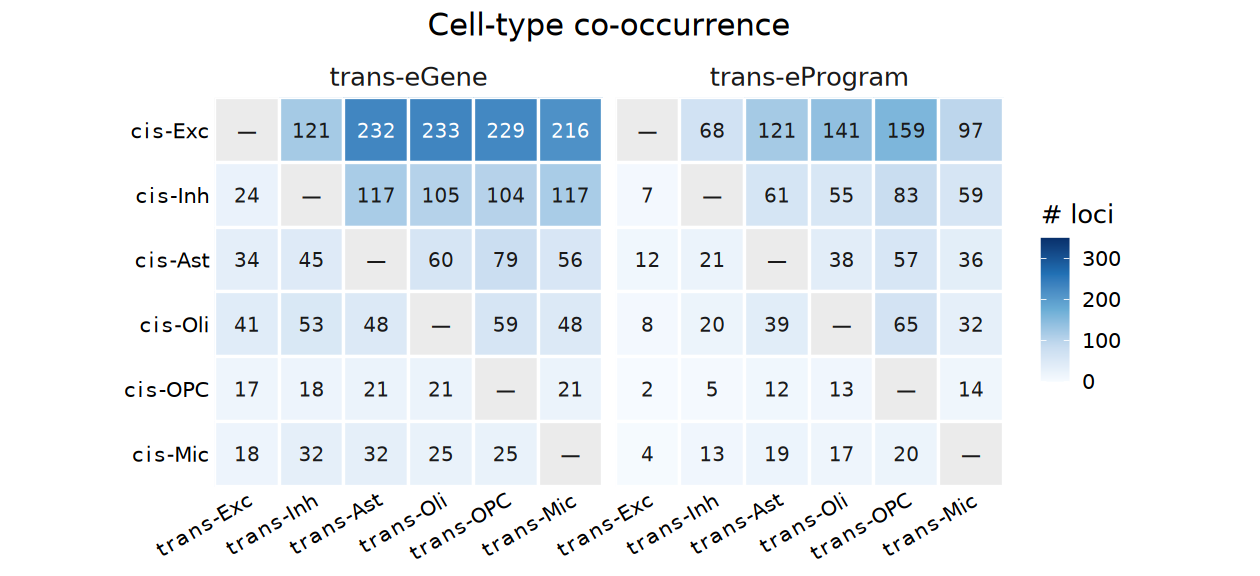

In [2]:
res$fill <- ifelse(res$is_diagonal, NA, res$n_loci)
res$label <- ifelse(res$is_diagonal, "\u2014", res$n_loci)
res$cis_cell <- factor(res$cis_cell, levels = rev(levels(res$cis_cell)))

p <- ggplot(res, aes(x = trans_cell, y = cis_cell)) +
  geom_tile(aes(fill = fill), colour = "white", linewidth = 0.7) +
  geom_text(aes(label = label, colour = !is.na(fill) & fill > 0.55 * 349),
            size = 4.2, show.legend = FALSE) +
  facet_wrap(~ trans_method, nrow = 1) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "grey10"), guide = "none") +
  scale_fill_gradientn(colours = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"),
                       limits = c(0, unique(res$color_upper)), na.value = "grey92",
                       name = "# loci") +
  scale_x_discrete(labels = function(x) parse(text = paste0("italic(trans)*'-", x, "'")),
                   expand = c(0, 0)) +
  scale_y_discrete(labels = function(x) parse(text = paste0("italic(cis)*'-", x, "'")),
                   expand = c(0, 0)) +
  coord_fixed() +
  labs(x = NULL, y = NULL, title = "Cell-type co-occurrence") +
  theme_classic(base_size = 15) +
  theme(plot.title = element_text(hjust = 0.5), axis.line = element_blank(),
        axis.ticks = element_blank(), axis.text.x = element_text(angle = 30, hjust = 1),
        strip.background = element_blank(), strip.text = element_text(size = 15))

options(repr.plot.width = 10.5, repr.plot.height = 4.8)
p